# BJT and MOSFET Circuits

A bipolar transistor and a MOSFET can be wired into the same networks. Figures and tables on this page share one layout of three columns: a label, then the BJT version and the MOSFET version side by side. Both versions of a circuit are drawn by the same few lines of Python. Where a circuit exists in only one of the two technologies, the cell of the other one says so. The page goes from one transistor in eight connections to forty-two circuits of two transistors in seven families.

The two-transistor circuits follow H. Pretl and M. Eberlein [1], who show the MOSFET versions. The BJT versions are obtained by swapping device for device. Circuits of [1] that use the body terminal, a thick-oxide device or the parasitic bipolar transistor of a MOSFET are left out. The symbols follow the drawing style of B. Razavi [2].

## Prerequisites

In [1]:
# HIDE/SHOW
# ! pip install -U numpy
# ! pip install -U matplotlib

## Visualization in Python

The folder of this notebook holds a small package, `razavi`, with the symbol geometry and a matplotlib renderer. Labels are set in Computer Modern through matplotlib's mathtext, so no TeX installation is needed.

In [2]:
# HIDE/SHOW
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}   # keep every figure at its full width
plt.rcParams['svg.hashsalt'] = 'fme'            # reproducible SVG output

from razavi import Transistor, BJT, MOSFET, show, symbol_sheet

IN, OUT = 'V_in', 'V_out'

## Utilizations

A circuit is a function of a drawing context `c`. `c.transistor(kind, at, anchor)` places a transistor of the class the drawing is made with. There are two classes, `BJT` and `MOSFET`, both derived from `Transistor`, so one function draws both columns.

| | BJT | MOSFET |
|---|---|---|
| **Class** | `BJT(Transistor)` | `MOSFET(Transistor)` |
| **Kind** `'n'`, `'p'` | npn, pnp | NMOS, PMOS |
| **Terminals** | `.b`, `.c`, `.e`: base, collector, emitter | `.g`, `.d`, `.s`: gate, drain, source |
| **Shared names** `.bg`, `.cd`, `.es` | give `.b`, `.c`, `.e` | give `.g`, `.d`, `.s` |
| **Name** `name=1` | $Q_1$ | $M_1$ |
| **Supply** `c.supply(p)` | $V_{CC}$ | $V_{DD}$ |
| **Size** `.size(text)` | draws nothing | writes a $W/L$ label beside the device |

The circuit functions use only the shared names, which read *base or gate*, *collector or drain* and *emitter or source*. `c.w(p0, p1, ...)` draws a wire, `c.dot(p)` a node, `c.port(p, label, side)` an open terminal, `c.gnd(p)` a ground, `c.ac(p)` an ac ground, `c.res(p, label)` a resistor and `c.load(p)` a load. `c.look(p, into, side, label)` marks the impedance seen at `p` with an arrow that has a 90-degree corner. `c.chain([...], x, y)` places a series stack of transistors, and `c.bus([...], x)` ties their bases or gates together. Coordinates are pixels on a 10-px grid with $y$ pointing down. Before drawing, all wire pieces and symbol leads are merged into continuous connectors.

`show(a, b)` draws the circuits `a` and `b` as two rows: their names in the first column, then the drawing made with `BJT` and the drawing made with `MOSFET`. The first docstring line gives the names, as `BJT name | MOSFET name` where the two differ. A name `-` means that the circuit has no such version, and that cell says so.

In [3]:
# HIDE/SHOW
def capacitor_to_ground(c, node):
    """second transistor, connected as a capacitor from `node` to ground"""
    t2 = c.transistor('n', (node[0], node[1] + 40), 'bg', side='right', rot=3, name=2)
    c.w(node, t2.bg)
    yb = t2.cd[1] + 20
    c.w(t2.cd, (t2.cd[0], yb), (t2.es[0], yb), t2.es)
    c.dot((node[0], yb)); c.w((node[0], yb), (node[0], yb + 10)); c.gnd((node[0], yb + 10))


def pass_device_and_capacitor(c, control):
    """first transistor as a pass device from the input to a node that the second one loads as a capacitor"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    c.w(t1.cd, (-30, 0)); c.port((-30, 0), IN, 'l')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), control, 't')
    node = (130, 0)
    c.w(t1.es, node); c.dot(node); c.w(node, (180, 0)); c.port((180, 0), OUT, 'r')
    capacitor_to_ground(c, node)

## What are Transistors?

- Transistors are three-terminal devices in which the voltage between two terminals controls the current through the third.
- In a bipolar junction transistor (BJT) the base-emitter voltage $V_{BE}$ controls the collector current $I_C$.
- In a MOS field-effect transistor (MOSFET) the gate-source voltage $V_{GS}$ controls the drain current $I_D$.

## Types of Transistors

- n-type transistors: npn BJT and NMOS FET
- p-type transistors: pnp BJT and PMOS FET, with all voltages and currents reversed

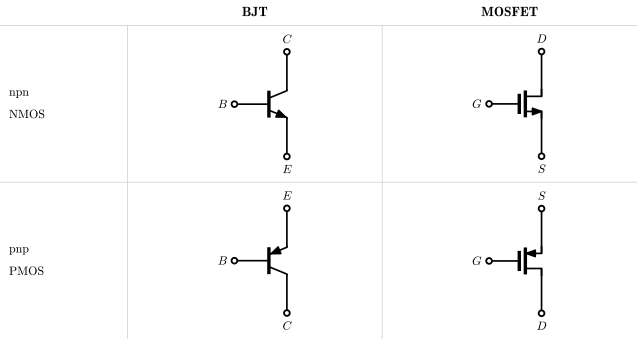

In [4]:
# HIDE/SHOW
def n_type(c):
    """npn | NMOS"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.cd, (0, -30)); c.port((0, -30), t.pin('cd'), 't')
    c.w(t.es, (0, 110)); c.port((0, 110), t.pin('es'), 'b')
    c.w(t.bg, (t.bg[0] - 30, 40)); c.port((t.bg[0] - 30, 40), t.pin('bg'), 'l')


def p_type(c):
    """pnp | PMOS"""
    t = c.transistor('p', (0, 0), 'es')
    c.w(t.es, (0, -30)); c.port((0, -30), t.pin('es'), 't')
    c.w(t.cd, (0, 110)); c.port((0, 110), t.pin('cd'), 'b')
    c.w(t.bg, (t.bg[0] - 30, 40)); c.port((t.bg[0] - 30, 40), t.pin('bg'), 'l')

show(n_type, p_type)

The two columns translate into each other term by term:

| | BJT | MOSFET |
|---|---|---|
| **Terminals** | base $B$, collector $C$, emitter $E$ | gate $G$, drain $D$, source $S$ |
| **Control voltage** | $V_{BE}$ | $V_{GS}$ |
| **Current law** | $I_C=I_S\,e^{V_{BE}/V_T}$ in the active region | $I_D=\tfrac12\mu_nC_{ox}\tfrac{W}{L}(V_{GS}-V_{TH})^2$ in saturation |
| **Transconductance** | $g_m=I_C/V_T$ | $g_m=2I_D/(V_{GS}-V_{TH})$ |
| **Output resistance** | $r_O=V_A/I_C$ | $r_O=1/(\lambda I_D)$ |
| **Control current** | $I_B=I_C/\beta$ | $I_G=0$ |
| **Size** | emitter area, through $I_S$ | $W/L$ |
| **Names** | $Q_1$, $Q_2$, supply $V_{CC}$ | $M_1$, $M_2$, supply $V_{DD}$ |

All relations on this page are first-order: $r_O$ and $\beta$ are taken as infinite unless they appear, and the body effect is neglected.

## Connections of One Transistor

One transistor can be connected in eight ways. Every circuit further down is two of these connections put together.

### Amplifier and Follower

The input drives the base or gate. The output is taken at the collector or drain (amplifier), or at the emitter or source (follower).

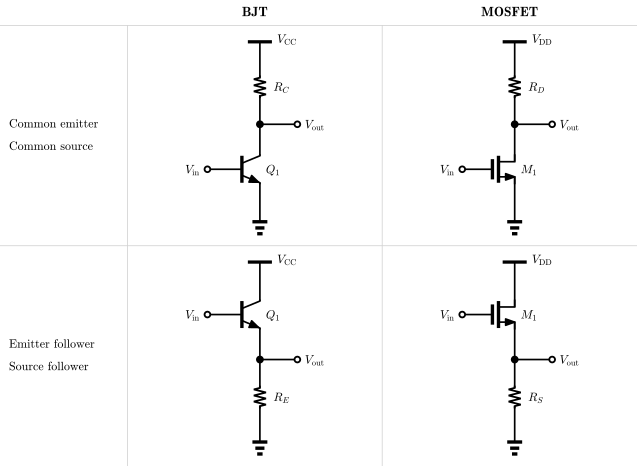

In [5]:
# HIDE/SHOW
def role_amplifier(c):
    """Common emitter | Common source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.supply((0, -120)); c.w((0, -120), (0, -100))
    out = (0, -20)
    c.w(c.res((0, -100), 'R_' + t1.pin('cd')), t1.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), OUT, 'r')
    c.w(t1.es, (0, 100)); c.gnd((0, 100))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), IN, 'l')


def role_follower(c):
    """Emitter follower | Source follower"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    out = (0, 100)
    c.w(t1.es, (0, 120)); c.dot(out)
    c.w(out, (50, 100)); c.port((50, 100), OUT, 'r')
    c.w(c.res((0, 120), 'R_' + t1.pin('es')), (0, 200)); c.gnd((0, 200))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), IN, 'l')

show(role_amplifier, role_follower)

| | BJT | MOSFET |
|---|---|---|
| **Amplifier** | $A_v=-g_mR_C$ | $A_v=-g_mR_D$ |
| **Follower** | The common-collector stage: $A_v=\dfrac{g_mR_E}{1+g_mR_E}$ | The common-drain stage: $A_v=\dfrac{g_mR_S}{1+g_mR_S}$ |

### Current Buffer and Current Source

The base or gate is held at a fixed voltage. A current pushed into the emitter or source comes out of the collector or drain (current buffer). With the emitter or source grounded, the device sets the current itself (current source).

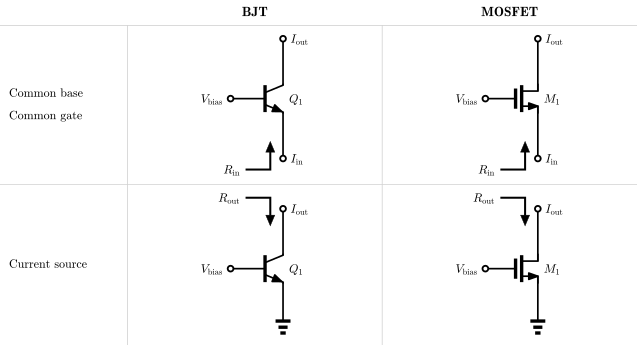

In [6]:
# HIDE/SHOW
def role_current_buffer(c):
    """Common base | Common gate"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out', 'r')
    c.w(t1.es, (0, 120)); c.port((0, 120), 'I_in', 'r'); c.look((0, 120), 'u', 'l', 'R_in')
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), 'V_bias', 'l')


def role_current_source(c):
    """Current source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out', 'r'); c.look((0, -40), 'd', 'l', 'R_out')
    c.w(t1.es, (0, 100)); c.gnd((0, 100))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), 'V_bias', 'l')

show(role_current_buffer, role_current_source)

| | BJT | MOSFET |
|---|---|---|
| **Current buffer** | $I_\mathrm{out}=\dfrac{\beta}{\beta+1}I_\mathrm{in}$, $R_\mathrm{in}\approx1/g_m$ | $I_\mathrm{out}=I_\mathrm{in}$, $R_\mathrm{in}\approx1/g_m$ |
| **Current source** | $I_\mathrm{out}=I_S\,e^{V_\mathrm{bias}/V_T}$, $R_\mathrm{out}=r_O$ | $I_\mathrm{out}=\tfrac12\mu_nC_{ox}\tfrac{W}{L}(V_\mathrm{bias}-V_{TH})^2$, $R_\mathrm{out}=r_O$ |

### Diode and Switch

With the base tied to the collector, or the gate to the drain, the transistor is a two-terminal diode. Driven fully on and off, it is a switch.

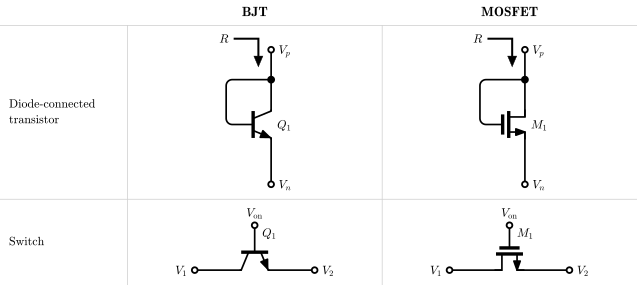

In [7]:
# HIDE/SHOW
def role_diode(c):
    """Diode-connected transistor"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    top = (0, -20)
    c.w(t1.cd, (0, -60)); c.dot(top); c.port((0, -60), 'V_p', 'r'); c.look((0, -60), 'd', 'l', 'R')
    c.w(t1.bg, (t1.bg[0] - 20, 40), (t1.bg[0] - 20, -20), top)
    c.w(t1.es, (0, 120)); c.port((0, 120), 'V_n', 'r')


def role_switch(c):
    """Switch"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    c.w(t1.cd, (t1.cd[0] - 40, 0)); c.port((t1.cd[0] - 40, 0), 'V_1', 'l')
    c.w(t1.es, (t1.es[0] + 40, 0)); c.port((t1.es[0] + 40, 0), 'V_2', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), 'V_on', 't')

show(role_diode, role_switch)

| | BJT | MOSFET |
|---|---|---|
| **Diode** | Conducts at $V_{BE}\approx0.7\,\mathrm{V}$, small-signal resistance $R=1/g_m$ | Conducts above $V_{TH}$, small-signal resistance $R=1/g_m$ |
| **Switch** | *Limited.* On in saturation: a few hundred millivolts of $V_{CE}$ remain, and the base current flows into the path | On in triode: no offset, $R_\mathrm{on}=\left[\mu_nC_{ox}\tfrac{W}{L}(V_{GS}-V_{TH})\right]^{-1}$ |

### Resistor and Capacitor

A transistor can also stand in for a passive element. This is where the two devices differ most.

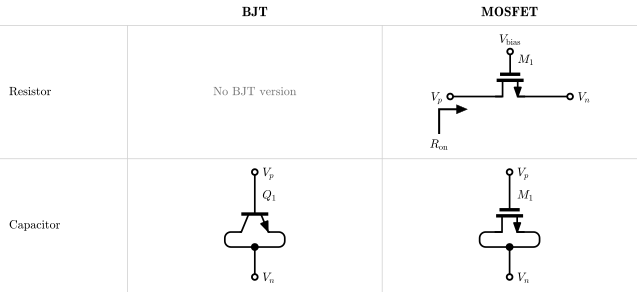

In [8]:
# HIDE/SHOW
def role_resistor(c):
    """- | Resistor"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    c.w(t1.cd, (t1.cd[0] - 40, 0)); c.port((t1.cd[0] - 40, 0), 'V_p', 'l'); c.look((t1.cd[0] - 40, 0), 'r', 'd', 'R_on')
    c.w(t1.es, (t1.es[0] + 40, 0)); c.port((t1.es[0] + 40, 0), 'V_n', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), 'V_bias', 't')


def role_capacitor(c):
    """Capacitor"""
    t1 = c.transistor('n', (0, 0), 'bg', side='right', rot=3, name=1)
    c.w(t1.bg, (0, -40)); c.port((0, -40), 'V_p', 'r')
    yb = t1.cd[1] + 20
    c.w(t1.cd, (t1.cd[0], yb), (t1.es[0], yb), t1.es); c.dot((0, yb))
    c.w((0, yb), (0, yb + 40)); c.port((0, yb + 40), 'V_n', 'r')

show(role_resistor, role_capacitor)

| | BJT | MOSFET |
|---|---|---|
| **Resistor** | *No BJT version.* A saturated BJT is not a linear resistor | Triode region: $R_\mathrm{on}$ as above, set by $V_\mathrm{bias}$ |
| **Capacitor** | *Limited.* Junction capacitance, usable only while the junctions stay reverse biased | Gate capacitance, $C\approx WLC_{ox}$ |

## Input and Output Impedances

The small-signal resistance seen when looking into one terminal of a transistor. An arrow with a 90-degree corner marks the terminal that is looked into, and *ac* marks a node held at a fixed voltage. The same arrow marks every impedance in the figures further down. The results are those of the summary inside the back cover of [2].

### Looking into the Base or Gate

The emitter or source is at ac ground, directly or through a resistor.

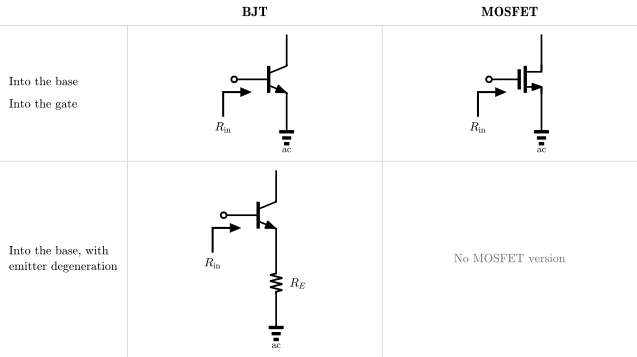

In [9]:
# HIDE/SHOW
def into_base(c):
    """Into the base | Into the gate"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.cd, (0, -20))
    c.w(t.es, (0, 100)); c.ac((0, 100))
    p = (t.bg[0] - 30, 40)
    c.w(t.bg, p); c.port(p, None); c.look(p, 'r', 'd', 'R_in')


def into_base_degenerated(c):
    """Into the base, with emitter degeneration | -"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.cd, (0, -20))
    c.w(t.es, (0, 100)); c.w(c.res((0, 100), 'R_' + t.pin('es')), (0, 180)); c.ac((0, 180))
    p = (t.bg[0] - 30, 40)
    c.w(t.bg, p); c.port(p, None); c.look(p, 'r', 'd', 'R_in')

show(into_base, into_base_degenerated)

| | BJT | MOSFET |
|---|---|---|
| **Into the base or gate** | $R_\mathrm{in}=r_\pi$ | $R_\mathrm{in}\approx\infty$ |
| **With degeneration** | $R_\mathrm{in}=r_\pi+(\beta+1)R_E$, for $V_A=\infty$ | *No MOSFET version.* The summary in [2] has no such entry: no current flows into the gate, so $R_\mathrm{in}\approx\infty$ with or without a source resistor |

### Looking into the Collector or Drain

The base or gate is at ac ground. The emitter or source is at ac ground, directly or through a resistor.

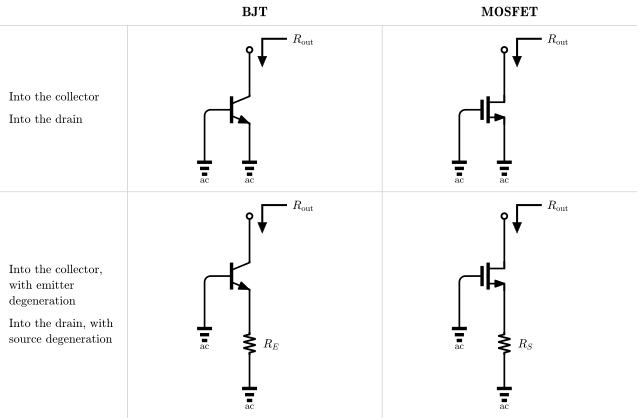

In [10]:
# HIDE/SHOW
def into_collector(c):
    """Into the collector | Into the drain"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.bg, (-60, 40), (-60, 100)); c.ac((-60, 100))
    c.w(t.es, (0, 100)); c.ac((0, 100))
    p = (0, -40)
    c.w(t.cd, p); c.port(p, None); c.look(p, 'd', 'r', 'R_out')


def into_collector_degenerated(c):
    """Into the collector, with emitter degeneration | Into the drain, with source degeneration"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.bg, (-60, 40), (-60, 100)); c.ac((-60, 100))
    c.w(t.es, (0, 100)); c.w(c.res((0, 100), 'R_' + t.pin('es')), (0, 180)); c.ac((0, 180))
    p = (0, -40)
    c.w(t.cd, p); c.port(p, None); c.look(p, 'd', 'r', 'R_out')

show(into_collector, into_collector_degenerated)

| | BJT | MOSFET |
|---|---|---|
| **Into the collector or drain** | $R_\mathrm{out}=r_O$ | $R_\mathrm{out}=r_O$ |
| **With degeneration** | $R_\mathrm{out}=(1+g_mr_O)(R_E\parallel r_\pi)+r_O$ | $R_\mathrm{out}=(1+g_mr_O)R_S+r_O$ |

### Looking into the Emitter or Source

The collector or drain is tied to a load, drawn as a box. The base or gate is at ac ground, directly or through a resistor.

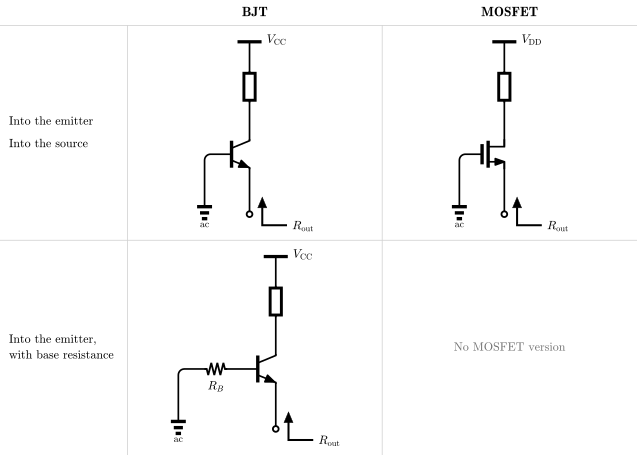

In [11]:
# HIDE/SHOW
def into_emitter(c):
    """Into the emitter | Into the source"""
    t = c.transistor('n', (0, 0), 'cd')
    c.supply((0, -100)); c.w((0, -100), (0, -80)); c.w(c.load((0, -80)), t.cd)
    c.w(t.bg, (-60, 40), (-60, 100)); c.ac((-60, 100))
    p = (0, 120)
    c.w(t.es, p); c.port(p, None); c.look(p, 'u', 'r', 'R_out')


def into_emitter_base_resistance(c):
    """Into the emitter, with base resistance | -"""
    t = c.transistor('n', (0, 0), 'cd')
    c.supply((0, -100)); c.w((0, -100), (0, -80)); c.w(c.load((0, -80)), t.cd)
    c.w(t.bg, (t.bg[0] - 10, 40))
    left = c.res((t.bg[0] - 10, 40), 'R_' + t.pin('bg'), to='left')
    c.w(left, (left[0] - 20, 40), (left[0] - 20, 100)); c.ac((left[0] - 20, 100))
    p = (0, 120)
    c.w(t.es, p); c.port(p, None); c.look(p, 'u', 'r', 'R_out')

show(into_emitter, into_emitter_base_resistance)

| | BJT | MOSFET |
|---|---|---|
| **Into the emitter or source** | $R_\mathrm{out}=\dfrac{1}{g_m}$, for $V_A=\infty$ | $R_\mathrm{out}=\dfrac{1}{g_m}$, for $\lambda=0$ |
| **With base resistance** | $R_\mathrm{out}=\dfrac{1}{g_m}+\dfrac{R_B}{\beta+1}$, for $V_A=\infty$ | *No MOSFET version.* The summary in [2] has no such entry: no current flows in a gate resistor, so $R_\mathrm{out}=1/g_m$ as in the row above |

## Voltage Gain Equations

The small-signal voltage gain $A_v=v_\mathrm{out}/v_\mathrm{in}$ of the three amplifier connections, as in the summary inside the back cover of [2].

### Common-Emitter and Common-Source Stages

The input drives the base or gate, and the output is taken at the collector or drain. A resistor in the emitter or source degenerates the stage.

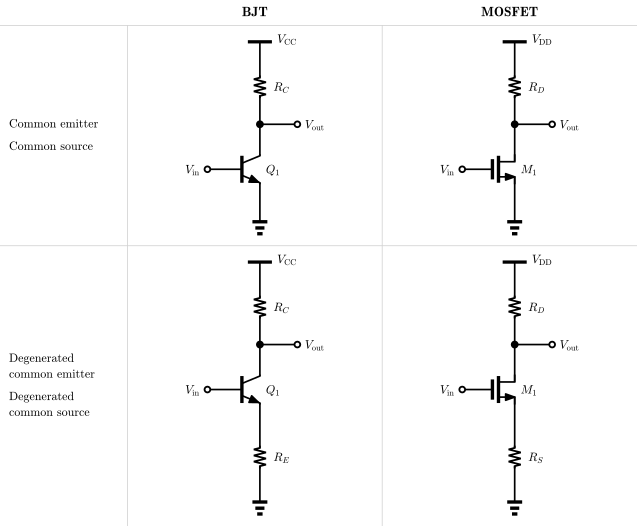

In [12]:
# HIDE/SHOW
def role_amplifier(c):
    """Common emitter | Common source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.supply((0, -120)); c.w((0, -120), (0, -100))
    out = (0, -20)
    c.w(c.res((0, -100), 'R_' + t1.pin('cd')), t1.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), OUT, 'r')
    c.w(t1.es, (0, 100)); c.gnd((0, 100))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), IN, 'l')


def gain_degenerated(c):
    """Degenerated common emitter | Degenerated common source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.supply((0, -120)); c.w((0, -120), (0, -100))
    out = (0, -20)
    c.w(c.res((0, -100), 'R_' + t1.pin('cd')), t1.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), OUT, 'r')
    c.w(t1.es, (0, 100)); c.w(c.res((0, 100), 'R_' + t1.pin('es')), (0, 180)); c.gnd((0, 180))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), IN, 'l')

show(role_amplifier, gain_degenerated)

| | BJT | MOSFET |
|---|---|---|
| **Amplifier** | $A_v=-g_m(R_C\parallel r_O)$ | $A_v=-g_m(R_D\parallel r_O)$ |
| **Degenerated amplifier** | $A_v=-\dfrac{R_C}{\dfrac{1}{g_m}+R_E}$, for $V_A=\infty$ | $A_v=-\dfrac{R_D}{\dfrac{1}{g_m}+R_S}$, for $\lambda=0$ |

### Common-Base or Common-Gate Stage and Follower

In the common-base or common-gate stage the input drives the emitter or source through a resistor. In the follower the output is taken at the emitter or source.

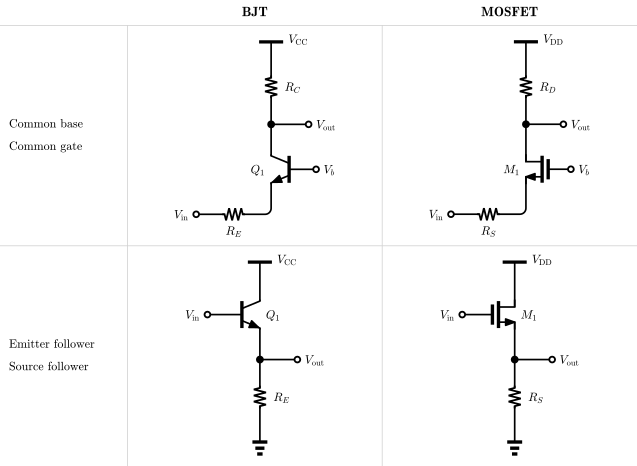

In [13]:
# HIDE/SHOW
def gain_buffer(c):
    """Common base | Common gate"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', name=1, lbl='l')
    c.supply((0, -120)); c.w((0, -120), (0, -100))
    out = (0, -20)
    c.w(c.res((0, -100), 'R_' + t1.pin('cd')), t1.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), OUT, 'r')
    c.w(t1.bg, (t1.bg[0] + 20, 40)); c.port((t1.bg[0] + 20, 40), 'V_b', 'r')
    c.w(t1.es, (0, 100), (-20, 100))
    left = c.res((-20, 100), 'R_' + t1.pin('es'), to='left')
    c.w(left, (left[0] - 20, 100)); c.port((left[0] - 20, 100), IN, 'l')


def role_follower(c):
    """Emitter follower | Source follower"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    out = (0, 100)
    c.w(t1.es, (0, 120)); c.dot(out)
    c.w(out, (50, 100)); c.port((50, 100), OUT, 'r')
    c.w(c.res((0, 120), 'R_' + t1.pin('es')), (0, 200)); c.gnd((0, 200))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), IN, 'l')

show(gain_buffer, role_follower)

| | BJT | MOSFET |
|---|---|---|
| **Common base or gate** | $A_v=\dfrac{R_C}{\dfrac{1}{g_m}+R_E}$, for $V_A=\infty$ | $A_v=\dfrac{R_D}{\dfrac{1}{g_m}+R_S}$, for $\lambda=0$ |
| **Follower** | $A_v=\dfrac{R_E\parallel r_O}{\dfrac{1}{g_m}+R_E\parallel r_O}$ | $A_v=\dfrac{R_S\parallel r_O}{\dfrac{1}{g_m}+R_S\parallel r_O}$ |

## Circuits of Two Transistors

The forty-two circuits are grouped into seven families by what the pair does. Inside a family the circuits come in pairs: the second circuit of a pair is the first one with a single change. The number in parentheses is the figure number in [1].

| Family | Circuits | The one change |
|---|---|---|
| **Bias Circuits** | 1. Voltage divider (34), 2. PTAT generator (26) | Both bases or gates go to the top of the stack |
|  | 3. Bias generator (24), 4. Tie cell (3) | The diode connection moves from the n-type to the p-type device |
|  | 5. Current mirror (7), 6. Current divider (35) | The devices are stacked, and the current enters between them |
| **Gain Stages** | 7. Active load (10), 8. Inverter (1) | The load is driven by the input as well |
|  | 9. Diode load (17), 10. Folded diode load (18) | The load moves beside the amplifying device |
|  | 11. Degeneration (20), 12. Tunable degeneration (21) | The lower device gets its own bias |
| **Buffers** | 13. Follower (9), 14. Push-pull follower (19) | A complementary follower replaces the current source |
|  | 15. Current buffer (13), 16. Stacked current buffers (12) | A second buffer replaces the current source |
|  | 17. Two outputs (22), 18. Two paths (23) | The amplifier becomes a follower, and the two signal currents meet in one output |
| **Feedback Pairs** | 19. Cascode (11), 20. Regulated cascode (48) | An amplifier senses the emitter or source of the buffer and drives its base or gate |
|  | 21. Flipped follower (47), 22. Active inductor (33) | The same loop, seen from the lower node |
|  | 23. Differential pair (8), 24. Cross-coupled pair (28) | Each base or gate goes to the opposite collector or drain |
| **Circuit Elements** | 25. Controlled resistor (41), 26. Large resistor (42) | The devices bias each other, without a bias current |
|  | 27. Varactor (30), 28. Anti-parallel capacitors (32) | The two capacitors are connected in parallel and in opposite directions |
|  | 29. Anti-parallel diodes (31), 30. Ultra-low-power diode (43) | The devices are put in series, each controlled from the far terminal |
|  | 31. Level shift (44), 32. Linear I-to-V converter (45) | A bias voltage fixes the sum of the two control voltages |
| **Switched Circuits** | 33. Transmission gate (14), 34. Multiplexer (15) | The two switches share only the output |
|  | 35. Sample-and-hold (36), 36. Low-pass filter (38) | A fixed bias replaces the clock |
|  | 37. Peak detector (39), 38. Voltage doubler (40) | Diode and capacitor change places |
| **Logic Gates** | 39. NAND (5), 40. NOR (6) | Series becomes parallel |
|  | 41. XNOR (4), 42. Mixer (37) | Logic levels become analog signals |

Of the forty-two circuits, 21 carry over to the BJT unchanged and 6 with a restriction, marked *Limited* in the BJT column. The other 15 rely on a MOSFET as a linear resistor, a gate capacitor or a switch without control current. They have no working BJT version: their BJT cell says so in the figure, and says why in the table.

## Bias Circuits

Circuits that set a dc voltage or a dc current.

### Voltage Divider and PTAT Generator

Two devices of the same type are stacked and carry the same current. In the divider each device is diode-connected. In the PTAT generator both bases or gates go to the top of the stack.

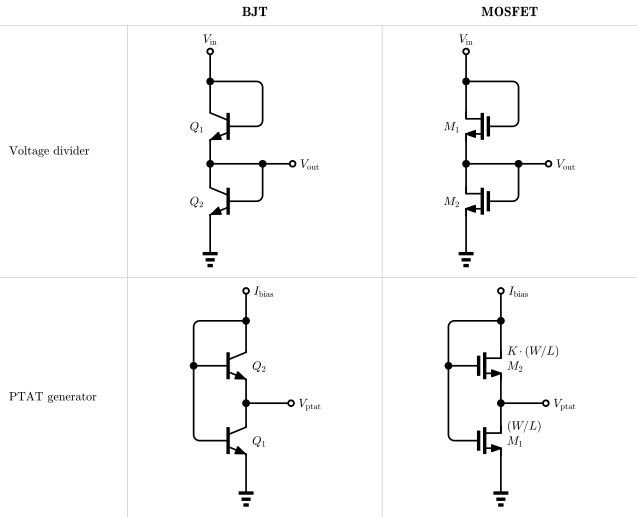

In [14]:
# HIDE/SHOW
def voltage_divider(c):
    """Voltage divider"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0, side='right')
    top = (0, -20)
    c.port((0, -60), IN, 't'); c.w((0, -60), top, t1.cd); c.dot(top)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    xt = 70
    c.w(t1.bg, (xt, t1.bg[1]), (xt, top[1]), top)
    c.w(t2.bg, (xt, t2.bg[1]), (xt, j[1]), j); c.dot((xt, j[1])); c.dot(j)
    c.w((xt, j[1]), (xt + 40, j[1])); c.port((xt + 40, j[1]), OUT, 'r')


def ptat_generator(c):
    """PTAT generator"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    t2.size('K·(W/L)'); t1.size('(W/L)')
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    top = (0, -20); c.w(t2.cd, top); c.dot(top); c.w(top, (0, -60)); c.port((0, -60), 'I_bias', 'r')
    xg = -70
    c.w(top, (xg, top[1]), (xg, t1.bg[1])); c.w(t2.bg, (xg, t2.bg[1])); c.w(t1.bg, (xg, t1.bg[1])); c.dot((xg, t2.bg[1]))
    c.dot(j); c.w(j, (60, j[1])); c.port((60, j[1]), 'V_ptat', 'r')

show(voltage_divider, ptat_generator)

| | BJT | MOSFET |
|---|---|---|
| **1. Voltage divider** | $V_\mathrm{out}=V_\mathrm{in}/2$ for matched devices: each drops one $V_{BE}$ | $V_\mathrm{out}=V_\mathrm{in}/2$ for matched devices: each drops one $V_{GS}$ |
| **2. PTAT generator** | *Limited.* $Q_1$ saturates. Its $V_{CE}$ is of the order of $V_T$ | Weak inversion: $V_\mathrm{ptat}=V_T\ln(1+K)$ with $V_T=kT/q$ |

### Bias Generator and Tie Cell

A p-type device sits on the supply side and an n-type device on the ground side. One of the two is diode-connected and sets the level.

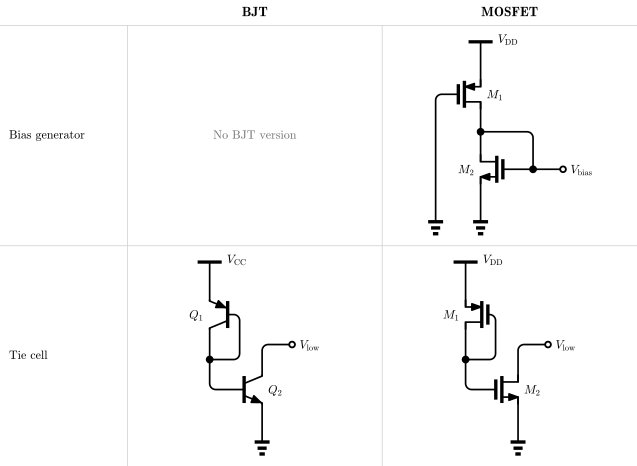

In [15]:
# HIDE/SHOW
def bias_generator(c):
    """- | Bias generator"""
    (t1, t2), (j,) = c.chain([('p', 1), ('n', 2, {'side': 'right'})], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.es)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    xg = -60
    c.w(t1.bg, (xg, t1.bg[1]), (xg, t2.es[1] + 20)); c.gnd((xg, t2.es[1] + 20))
    c.w(j, (70, j[1]), (70, t2.bg[1])); c.dot(j); c.dot((70, t2.bg[1]))
    c.w((70, t2.bg[1]), t2.bg); c.w((70, t2.bg[1]), (110, t2.bg[1])); c.port((110, t2.bg[1]), 'V_bias', 'r')


def tie_cell(c):
    """Tie cell"""
    p = c.transistor('p', (0, 0), 'es', side='right', name=1)
    c.supply((0, -20)); c.w((0, -20), p.es)
    n = c.transistor('n', (30, 140), 'bg', name=2)
    c.w(n.bg, (0, n.bg[1]), p.cd)
    tap = (0, 100)
    c.w(p.bg, (p.bg[0], 100), tap); c.dot(tap)
    c.w(n.cd, (n.cd[0], p.cd[1]), (n.cd[0] + 40, p.cd[1])); c.port((n.cd[0] + 40, p.cd[1]), 'V_low', 'r')
    g = (n.es[0], n.es[1] + 20); c.gnd(g); c.w(n.es, g)

show(bias_generator, tie_cell)

| | BJT | MOSFET |
|---|---|---|
| **3. Bias generator** | *No BJT version.* A grounded base would put the whole supply across the emitter-base junction | $M_1$ is a current source and $M_2$ a diode: $V_\mathrm{bias}=V_{GS2}$ |
| **4. Tie cell** | *Limited.* Two junctions in series across the supply: needs a series resistor | Diode $M_1$ turns $M_2$ on, which holds the output at ground. No gate is wired to a supply rail |

### Current Mirror and Current Divider

Both bases or gates are tied together, so the device sizes set a current ratio. The mirror copies a current. The divider splits one.

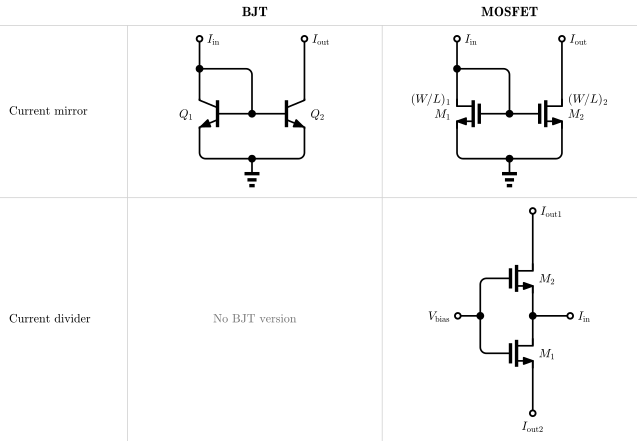

In [16]:
# HIDE/SHOW
def current_mirror(c):
    """Current mirror"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', name=1, lbl='l')
    t2 = c.transistor('n', (140, 0), 'cd', name=2, lbl='r')
    t1.size('(W/L)_1'); t2.size('(W/L)_2')
    top = (0, -20)
    c.w(t1.cd, top); c.dot(top); c.w(top, (0, -60)); c.port((0, -60), 'I_in', 'r')
    c.w(t2.cd, (140, -60)); c.port((140, -60), 'I_out', 'r')
    gy = t1.bg[1]
    c.w(t1.bg, t2.bg); mx = (t1.bg[0] + t2.bg[0]) / 2
    c.dot((mx, gy)); c.w((mx, gy), (mx, top[1]), top)
    yb = t1.es[1] + 20
    c.w(t1.es, (0, yb), (140, yb), t2.es)
    c.dot((70, yb)); c.w((70, yb), (70, yb + 10)); c.gnd((70, yb + 10))


def current_divider(c):
    """- | Current divider"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    xin = -70
    c.bus([t2, t1], xin)
    yg = j[1]; c.dot((xin, yg)); c.w((xin, yg), (xin - 30, yg)); c.port((xin - 30, yg), 'V_bias', 'l')
    c.w(t2.cd, (0, -50)); c.port((0, -50), 'I_out1', 'r')
    c.w(t1.es, (0, t1.es[1] + 40)); c.port((0, t1.es[1] + 40), 'I_out2', 'b')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), 'I_in', 'r')

show(current_mirror, current_divider)

| | BJT | MOSFET |
|---|---|---|
| **5. Current mirror** | $I_\mathrm{out}=\dfrac{I_\mathrm{in}}{1+2/\beta}$ for equal devices. The ratio follows the emitter areas | $I_\mathrm{out}=\dfrac{(W/L)_2}{(W/L)_1}\,I_\mathrm{in}$ |
| **6. Current divider** | *No BJT version.* The exponential law gives no linear split | $I_\mathrm{in}$ splits between the two outputs in a fixed ratio set by the sizes, at any signal level |

## Gain Stages

One device amplifies. The other is its load or its degeneration.

### Active Load and Inverter

An n-type and a p-type device are stacked between the rails, with the output at their junction. With the upper base or gate at a fixed bias, the upper device is a current-source load. With both inputs tied together, both devices amplify.

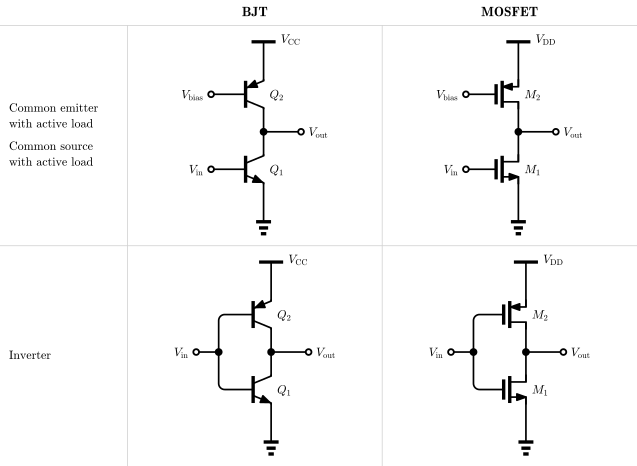

In [17]:
# HIDE/SHOW
def active_load(c):
    """Common emitter with active load | Common source with active load"""
    (t2, t1), (j,) = c.chain([('p', 2), ('n', 1)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t2.es)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')


def inverter(c):
    """Inverter"""
    (p, n), (j,) = c.chain([('p', 2), ('n', 1)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), p.top)
    g = (0, n.es[1] + 20); c.gnd(g); c.w(n.es, g)
    xin = -70
    c.bus([p, n], xin)
    c.dot((xin, j[1])); c.w((xin, j[1]), (xin - 30, j[1])); c.port((xin - 30, j[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')

show(active_load, inverter)

| | BJT | MOSFET |
|---|---|---|
| **7. Active load** | $A_v=-g_{m1}\,(r_{O1}\parallel r_{O2})$ | $A_v=-g_{m1}\,(r_{O1}\parallel r_{O2})$ |
| **8. Inverter** | *Limited.* $V_{CC}$ lies across two base-emitter junctions, so it must stay near $2V_{BE}$ | $A_v=-(g_{m1}+g_{m2})(r_{O1}\parallel r_{O2})$ around the switching point. As a logic gate the output swings from rail to rail |

### Stacked and Folded Diode Loads

The load is a diode-connected device of the same type as the amplifying device. It sits on top of that device, or beside it with its own share of a bias current.

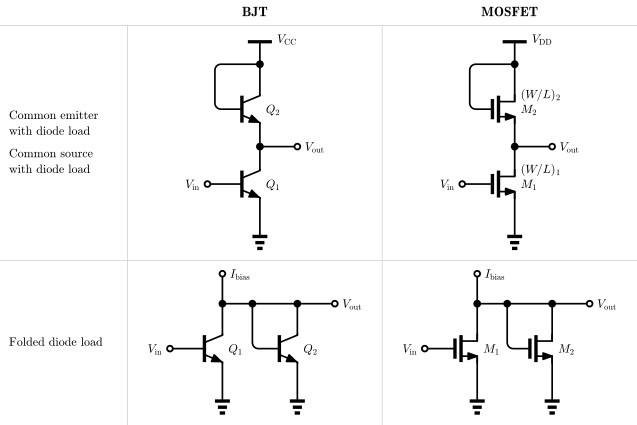

In [18]:
# HIDE/SHOW
def diode_load(c):
    """Common emitter with diode load | Common source with diode load"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    t2.size('(W/L)_2'); t1.size('(W/L)_1')
    top = (0, -20); c.supply((0, -40)); c.w((0, -40), top, t2.cd); c.dot(top)
    c.w(t2.bg, (t2.bg[0] - 20, t2.bg[1]), (t2.bg[0] - 20, top[1]), top)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')


def folded_diode_load(c):
    """Folded diode load"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (100, 0), 'cd', name=2)
    for t in (t1, t2):
        g = (t.es[0], t.es[1] + 20); c.gnd(g); c.w(t.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    node = (0, -20)
    c.w(t1.cd, (0, -60)); c.dot(node); c.port((0, -60), 'I_bias', 'r')
    c.w(node, (150, -20)); c.port((150, -20), OUT, 'r')
    c.w(t2.cd, (100, -20)); c.dot((100, -20))                         # the second transistor is diode-connected
    c.w((40, -20), (40, t2.bg[1]), t2.bg); c.dot((40, -20))

show(diode_load, folded_diode_load)

| | BJT | MOSFET |
|---|---|---|
| **9. Diode load** | $A_v=-\dfrac{g_{m1}}{g_{m2}}=-1$, because both devices carry the same current | $A_v=-\dfrac{g_{m1}}{g_{m2}}=-\sqrt{\dfrac{(W/L)_1}{(W/L)_2}}$ |
| **10. Folded diode load** | $A_v=-\dfrac{g_{m1}}{g_{m2}}=-\dfrac{I_{C1}}{I_{C2}}$ | $A_v=-\dfrac{g_{m1}}{g_{m2}}$, output referred to ground, no body effect in $M_2$ |

### Fixed and Tunable Degeneration

The lower device takes the place of a resistor in the source of the upper one. Its gate is driven by the input, or by a separate bias.

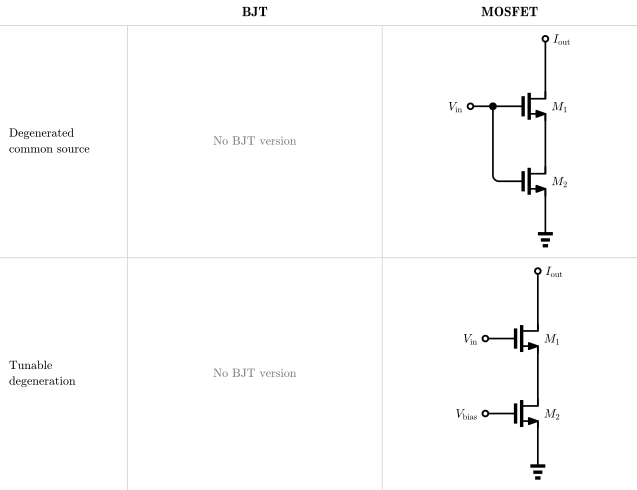

In [19]:
# HIDE/SHOW
def degeneration(c):
    """- | Degenerated common source"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.cd, (0, -50)); c.port((0, -50), 'I_out', 'r')
    xin = -70
    c.bus([t1, t2], xin)
    yi = t1.bg[1]; c.dot((xin, yi)); c.w((xin, yi), (xin - 30, yi)); c.port((xin - 30, yi), IN, 'l')


def tunable_degeneration(c):
    """- | Tunable degeneration"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.cd, (0, -50)); c.port((0, -50), 'I_out', 'r')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')

show(degeneration, tunable_degeneration)

| | BJT | MOSFET |
|---|---|---|
| **11. Degeneration** | *No BJT version.* The lower device would saturate, and a saturated BJT is not a linear resistor | $M_2$ works in triode. The pair acts as one transistor of greater length |
| **12. Tunable degeneration** | *No BJT version.* A BJT offers no bias-controlled linear resistance | $G_m=\dfrac{g_{m1}}{1+g_{m1}R_\mathrm{on2}}$, with $R_\mathrm{on2}$ set by $V_\mathrm{bias}$ |

## Buffers

The signal is passed on, as a voltage or as a current, at a different impedance level.

### Class-A and Push-Pull Followers

A follower passes a voltage. Its partner is a current source, or a complementary follower that takes over for the other signal polarity.

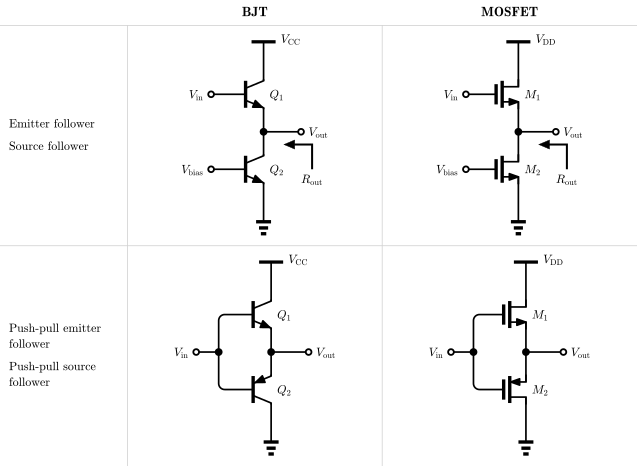

In [20]:
# HIDE/SHOW
def follower(c):
    """Emitter follower | Source follower"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r'); c.look((50, j[1]), 'l', 'd', 'R_out')


def push_pull(c):
    """Push-pull emitter follower | Push-pull source follower"""
    (t1, t2), (j,) = c.chain([('n', 1), ('p', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    g = (0, t2.cd[1] + 20); c.gnd(g); c.w(t2.cd, g)
    xin = -70
    c.bus([t1, t2], xin)
    yi = j[1]; c.dot((xin, yi)); c.w((xin, yi), (xin - 30, yi)); c.port((xin - 30, yi), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')

show(follower, push_pull)

| | BJT | MOSFET |
|---|---|---|
| **13. Follower** | $V_\mathrm{out}=V_\mathrm{in}-V_{BE1}$, $R_\mathrm{out}\approx1/g_{m1}$ | $V_\mathrm{out}=V_\mathrm{in}-V_{GS1}$, $R_\mathrm{out}\approx1/g_{m1}$ |
| **14. Push-pull follower** | No device conducts while $\lvert V_\mathrm{in}-V_\mathrm{out}\rvert<V_{BE}$ | No device conducts while $\lvert V_\mathrm{in}-V_\mathrm{out}\rvert<V_{TH}$ |

### Single and Stacked Current Buffers

A current buffer passes a current. Its partner is the current source that biases it, or a second buffer on top.

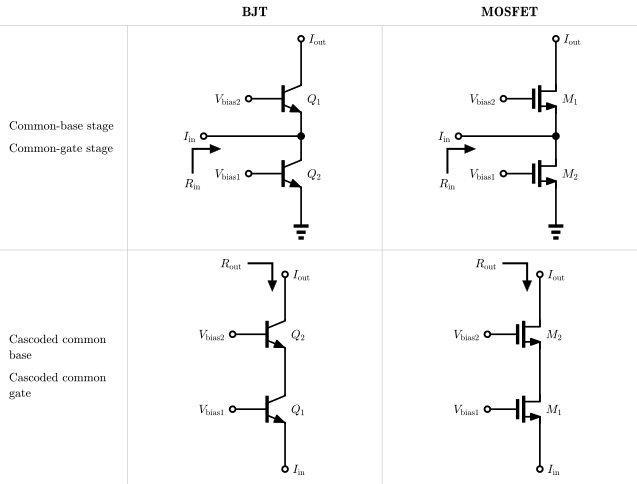

In [21]:
# HIDE/SHOW
def buffer_stage(c):
    """Common-base stage | Common-gate stage"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_bias2', 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias1', 'l')
    xl = t1.bg[0] - 90
    c.dot(j); c.w(j, (xl, j[1])); c.port((xl, j[1]), 'I_in', 'l'); c.look((xl, j[1]), 'r', 'd', 'R_in')
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out', 'r')


def stacked_buffers(c):
    """Cascoded common base | Cascoded common gate"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_bias1', 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias2', 'l')
    c.w(t2.cd, (0, -40)); c.port((0, -40), 'I_out', 'r'); c.look((0, -40), 'd', 'l', 'R_out')
    c.w(t1.es, (0, t1.es[1] + 40)); c.port((0, t1.es[1] + 40), 'I_in', 'r')

show(buffer_stage, stacked_buffers)

| | BJT | MOSFET |
|---|---|---|
| **15. Current buffer** | $R_\mathrm{in}\approx1/g_{m1}$. The signal current reaches the output almost unchanged | $R_\mathrm{in}\approx1/g_{m1}$. The signal current reaches the output unchanged |
| **16. Stacked current buffers** | The output resistance $R_\mathrm{out}$ rises with each device, up to about $\beta\,r_O$ | The output resistance $R_\mathrm{out}$ rises by about $g_mr_O$ with each device |

### Two Outputs and Two Paths

One input drives the base or gate of one device and the emitter or source of the other at the same time.

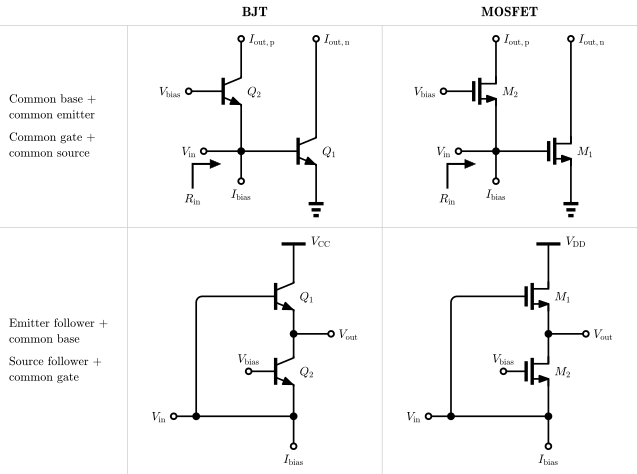

In [22]:
# HIDE/SHOW
def two_outputs(c):
    """Common base + common emitter | Common gate + common source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (-100, 0), 'es', name=2)
    yt = -110
    c.w(t1.cd, (0, yt)); c.port((0, yt), 'I_out,n', 'r')
    c.w(t2.cd, (-100, yt)); c.port((-100, yt), 'I_out,p', 'r')
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    nd = (-100, t1.bg[1])
    c.w(t2.es, nd); c.dot(nd); c.w(nd, t1.bg)
    c.w(nd, (-150, nd[1])); c.port((-150, nd[1]), IN, 'l'); c.look((-150, nd[1]), 'r', 'd', 'R_in')
    c.w(nd, (-100, nd[1] + 40)); c.port((-100, nd[1] + 40), 'I_bias', 'b')


def two_paths(c):
    """Emitter follower + common base | Source follower + common gate"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    inp = (0, t2.es[1] + 20); c.w(t2.es, inp); c.dot(inp); c.w(inp, (0, inp[1] + 40)); c.port((0, inp[1] + 40), 'I_bias', 'b')
    c.w(t2.bg, (t2.bg[0] - 20, t2.bg[1])); c.port((t2.bg[0] - 20, t2.bg[1]), 'V_bias', 't', dx=8)
    xl = -130
    c.w(inp, (xl, inp[1])); c.dot((xl, inp[1])); c.w((xl, inp[1]), (xl - 30, inp[1])); c.port((xl - 30, inp[1]), IN, 'l')
    c.w((xl, inp[1]), (xl, t1.bg[1]), t1.bg)
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')

show(two_outputs, two_paths)

| | BJT | MOSFET |
|---|---|---|
| **17. Two outputs** | The output currents change by $\mp g_mV_\mathrm{in}$ for equal $g_m$. $R_\mathrm{in}\approx1/g_{m2}$ | The output currents change by $\mp g_mV_\mathrm{in}$ for equal $g_m$. $R_\mathrm{in}\approx1/g_{m2}$ |
| **18. Two paths** | $A_v=1+\dfrac{g_{m2}}{g_{m1}}$ | $A_v=1+\dfrac{g_{m2}}{g_{m1}}$ |

## Feedback Pairs

The second device closes a loop around the first.

### Cascode and Regulated Cascode

A current buffer on top of an amplifier shields its collector or drain. In the regulated cascode a second device senses the emitter or source of the buffer and drives its base or gate.

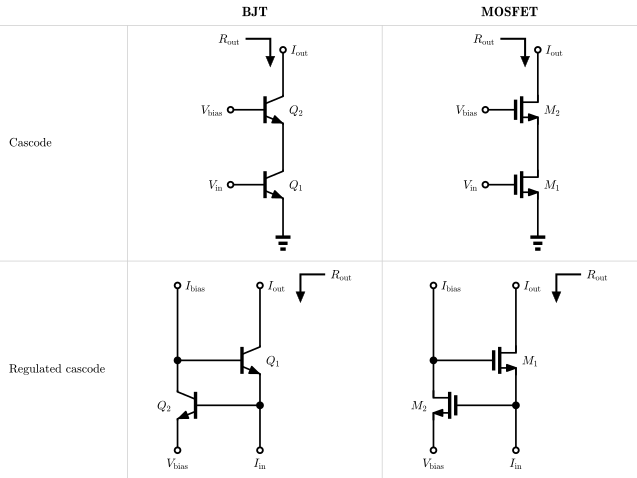

In [23]:
# HIDE/SHOW
def cascode(c):
    """Cascode"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    c.w(t2.cd, (0, -40)); c.port((0, -40), 'I_out', 'r'); c.look((0, -40), 'd', 'l', 'R_out')


def regulated_cascode(c):
    """Regulated cascode"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.w(t1.cd, (0, -60)); c.port((0, -60), 'I_out', 'r'); c.look((0, -60), 'd', 'r', 'R_out', gap=54)
    c.w(t1.es, (0, 160)); c.port((0, 160), 'I_in', 'b')
    t2 = c.transistor('n', (-110, 60), 'cd', side='right', name=2, lbl='l')
    gy = t1.bg[1]
    c.w(t2.cd, (-110, gy)); c.dot((-110, gy)); c.w((-110, gy), t1.bg)
    c.w((-110, gy), (-110, -60)); c.port((-110, -60), 'I_bias', 'r')
    c.w(t2.bg, (0, t2.bg[1])); c.dot((0, t2.bg[1]))
    c.w(t2.es, (-110, 160)); c.port((-110, 160), 'V_bias', 'b')

show(cascode, regulated_cascode)

| | BJT | MOSFET |
|---|---|---|
| **19. Cascode** | $R_\mathrm{out}\approx\beta\,r_{O2}$ at most | $R_\mathrm{out}\approx g_{m2}r_{O2}\,r_{O1}$ |
| **20. Regulated cascode** | $R_\mathrm{out}$ stays near $\beta\,r_{O1}$: the base current of $Q_1$ sets the limit | The loop multiplies $R_\mathrm{out}$ once more, by about $g_{m2}r_{O2}$ |

### Flipped Follower and Active Inductor

Both rows are the same loop: the upper device passes a signal from the lower node up to the bias node, and the lower device amplifies it back down. Driving the upper base or gate gives a follower. Looking into the lower node gives an inductor.

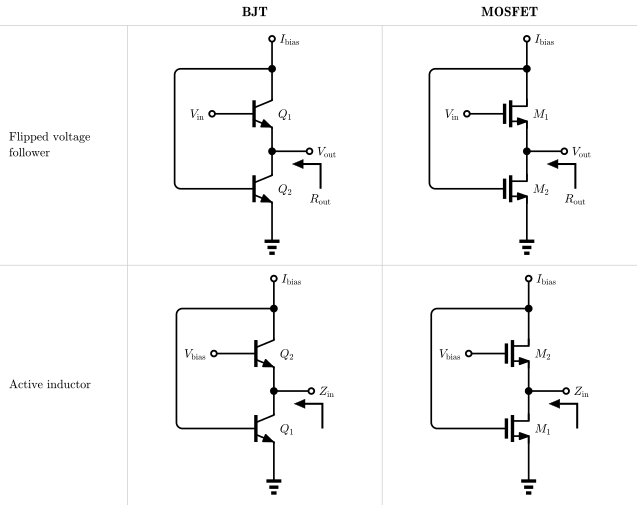

In [24]:
# HIDE/SHOW
def flipped_follower(c):
    """Flipped voltage follower"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    top = (0, -20); c.w(t1.cd, top); c.dot(top); c.w(top, (0, -60)); c.port((0, -60), 'I_bias', 'r')
    c.w(t1.bg, (t1.bg[0] - 40, t1.bg[1])); c.port((t1.bg[0] - 40, t1.bg[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r'); c.look((50, j[1]), 'l', 'd', 'R_out')
    xb = -130
    c.w(top, (xb, top[1]), (xb, t2.bg[1]), t2.bg)


def active_inductor(c):
    """Active inductor"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    top = (0, -20); c.w(t2.cd, top); c.dot(top); c.w(top, (0, -60)); c.port((0, -60), 'I_bias', 'r')
    c.w(t2.bg, (t2.bg[0] - 40, t2.bg[1])); c.port((t2.bg[0] - 40, t2.bg[1]), 'V_bias', 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), 'Z_in', 'r'); c.look((50, j[1]), 'l', 'd')
    xb = -130
    c.w(top, (xb, top[1]), (xb, t1.bg[1]), t1.bg)

show(flipped_follower, active_inductor)

| | BJT | MOSFET |
|---|---|---|
| **21. Flipped follower** | $V_\mathrm{out}=V_\mathrm{in}-V_{BE1}$, $R_\mathrm{out}\approx\dfrac{1}{g_{m1}\,g_{m2}r_{O1}}$ | $V_\mathrm{out}=V_\mathrm{in}-V_{GS1}$, $R_\mathrm{out}\approx\dfrac{1}{g_{m1}\,g_{m2}r_{O1}}$ |
| **22. Active inductor** | $Z_\mathrm{in}$ is $1/g_{m2}$ in parallel with $L\approx\dfrac{C_{\pi1}}{g_{m1}g_{m2}}$ | $Z_\mathrm{in}$ is $1/g_{m2}$ in parallel with $L\approx\dfrac{C_{GS1}}{g_{m1}g_{m2}}$ |

### Differential and Cross-Coupled Pairs

Two matched devices share a tail current. Connecting each base or gate to the opposite collector or drain turns the amplifier into a negative resistance.

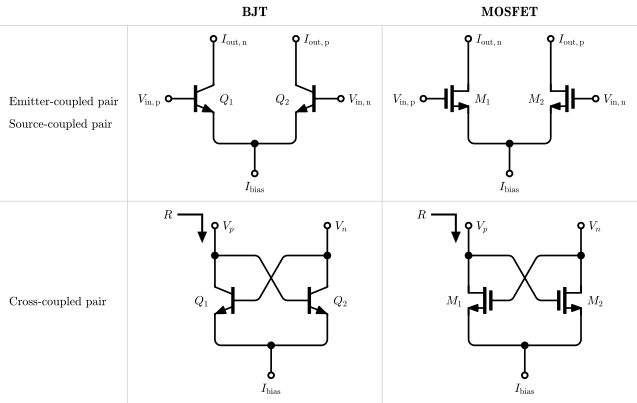

In [25]:
# HIDE/SHOW
def differential_pair(c):
    """Emitter-coupled pair | Source-coupled pair"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (110, 0), 'cd', side='right', name=2)
    c.w(t1.bg, (t1.bg[0] - 20, t1.bg[1])); c.port((t1.bg[0] - 20, t1.bg[1]), 'V_in,p', 'l')
    c.w(t2.bg, (t2.bg[0] + 20, t2.bg[1])); c.port((t2.bg[0] + 20, t2.bg[1]), 'V_in,n', 'r')
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out,n', 'r')
    c.w(t2.cd, (110, -40)); c.port((110, -40), 'I_out,p', 'r')
    yb = t1.es[1] + 20
    c.w(t1.es, (0, yb), (110, yb), t2.es); c.dot((55, yb))
    c.w((55, yb), (55, yb + 40)); c.port((55, yb + 40), 'I_bias', 'b')


def cross_coupled_pair(c):
    """Cross-coupled pair"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', name=1)
    t2 = c.transistor('n', (150, 0), 'cd', name=2)
    a, b = (0, -20), (150, -20)
    c.w(t1.cd, (0, -60)); c.dot(a); c.port((0, -60), 'V_p', 'r'); c.look((0, -60), 'd', 'l', 'R')
    c.w(t2.cd, (150, -60)); c.dot(b); c.port((150, -60), 'V_n', 'r')
    xl, xr = c.cross(75, a[1], t1.bg[1])                    # the two wires cross as an X
    c.w(a, (xl, a[1]), (xr, t2.bg[1]), t2.bg)
    c.w(b, (xr, b[1]), (xl, t1.bg[1]), t1.bg)
    ys = 100
    c.w(t1.es, (0, ys), (150, ys), t2.es); c.dot((75, ys)); c.w((75, ys), (75, ys + 40)); c.port((75, ys + 40), 'I_bias', 'b')

show(differential_pair, cross_coupled_pair)

| | BJT | MOSFET |
|---|---|---|
| **23. Differential pair** | $\Delta I_\mathrm{out}=I_\mathrm{bias}\tanh\dfrac{\Delta V_\mathrm{in}}{2V_T}$, $g_m=\dfrac{I_\mathrm{bias}}{2V_T}$ | $\Delta I_\mathrm{out}\approx g_m\,\Delta V_\mathrm{in}$, $g_m=\sqrt{\mu_nC_{ox}\tfrac{W}{L}\,I_\mathrm{bias}}$ |
| **24. Cross-coupled pair** | $R=-2/g_m$ between the two collectors | $R=-2/g_m$ between the two drains |

## Circuit Elements

The pair has two terminals and stands in for a resistor, a capacitor, a diode or a voltage source.

### Controlled and Large Resistors

A MOSFET in the triode region is a resistor between source and drain. One device sets the gate voltage of the other, or two devices in series bias each other close to cutoff.

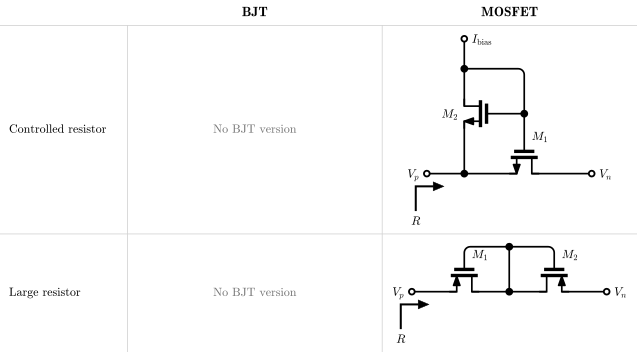

In [26]:
# HIDE/SHOW
def controlled_resistor(c):
    """- | Controlled resistor"""
    t1 = c.transistor('n', (0, 0), 'es', rot=1, name=1)
    tap = (-40, 0)
    c.w(t1.es, tap); c.dot(tap); c.w(tap, (-90, 0)); c.port((-90, 0), 'V_p', 'l'); c.look((-90, 0), 'r', 'd', 'R')
    c.w(t1.cd, (130, 0)); c.port((130, 0), 'V_n', 'r')
    t2 = c.transistor('n', (-40, -40), 'es', side='right', name=2)
    c.w(tap, t2.es)
    gn = (40, -80)
    c.w(t2.bg, gn); c.dot(gn); c.w(gn, t1.bg)
    tp = (-40, -140)
    c.w(t2.cd, tp); c.dot(tp); c.w(tp, (-40, -180)); c.port((-40, -180), 'I_bias', 'r')
    c.w(tp, (40, -140), gn)


def large_resistor(c):
    """- | Large resistor"""
    t1 = c.transistor('p', (0, 0), 'es', side='right', rot=3, name=1)
    t2 = c.transistor('p', (120, 0), 'cd', rot=1, name=2)
    c.w(t1.cd, (100, 0), t2.cd); c.dot((100, 0))
    c.w(t1.es, (-30, 0)); c.port((-30, 0), 'V_p', 'l'); c.look((-30, 0), 'r', 'd', 'R')
    c.w(t2.es, (230, 0)); c.port((230, 0), 'V_n', 'r')
    c.w((100, 0), (100, -60)); c.dot((100, -60))
    c.w(t1.bg, (t1.bg[0], -60), (100, -60))
    c.w(t2.bg, (t2.bg[0], -60), (100, -60))

show(controlled_resistor, large_resistor)

| | BJT | MOSFET |
|---|---|---|
| **25. Controlled resistor** | *No BJT version.* A BJT is not a linear resistor | $R=\dfrac{(W/L)_2}{(W/L)_1}\cdot\dfrac{1}{g_{m2}}$, set by $I_\mathrm{bias}$ |
| **26. Large resistor** | *No BJT version.* A BJT is not a linear resistor | Both gates at the common node keep each device nearly off: very large resistance $R$ for small voltages |

### Varactor and Anti-Parallel Capacitors

The gate of a MOSFET whose source and drain are tied together is one plate of a capacitor.

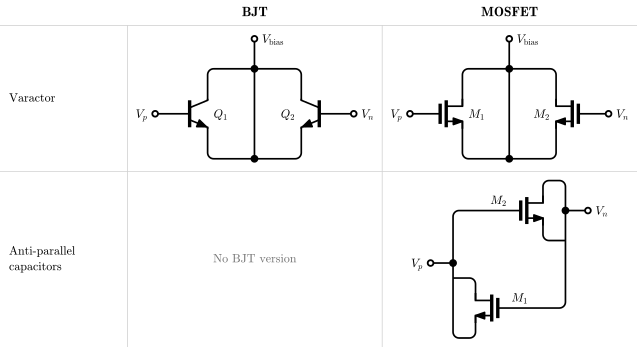

In [27]:
# HIDE/SHOW
def varactor(c):
    """Varactor"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (125, 0), 'cd', side='right', name=2)
    mx = 62.5
    c.w(t1.cd, (0, -20), (125, -20), t2.cd); c.dot((mx, -20))
    c.w(t1.es, (0, 100), (125, 100), t2.es); c.dot((mx, 100))
    c.w((mx, -20), (mx, 100))
    c.w((mx, -20), (mx, -60)); c.port((mx, -60), 'V_bias', 'r')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_p', 'l')
    c.w(t2.bg, (t2.bg[0] + 30, t2.bg[1])); c.port((t2.bg[0] + 30, t2.bg[1]), 'V_n', 'r')


def antiparallel_capacitors(c):
    """- | Anti-parallel capacitors"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right')
    t1.name(1, 'r', dy=-14)
    t2 = c.transistor('n', (90, -130), 'cd')
    t2.name(2, 'l', dy=-14)
    xl, xr = -30, 120
    c.w(t1.cd, (xl, 0)); c.w(t1.es, (xl, 80)); c.w(t2.bg, (xl, t2.bg[1])); c.w((xl, t2.bg[1]), (xl, 80))
    c.dot((xl, -20)); c.w((xl, -20), (xl - 30, -20)); c.port((xl - 30, -20), 'V_p', 'l')
    c.w(t2.cd, (xr, t2.cd[1])); c.w(t2.es, (xr, t2.es[1])); c.w(t1.bg, (xr, t1.bg[1])); c.w((xr, t1.bg[1]), (xr, t2.cd[1]))
    c.dot((xr, -90)); c.w((xr, -90), (xr + 30, -90)); c.port((xr + 30, -90), 'V_n', 'r')

show(varactor, antiparallel_capacitors)

| | BJT | MOSFET |
|---|---|---|
| **27. Varactor** | *Limited.* Junction capacitances, tuned by a reverse bias | Capacitance between the two gates, tuned by $V_\mathrm{bias}$ |
| **28. Anti-parallel capacitors** | *No BJT version.* For either polarity one device would have forward-biased junctions and conduct | Two gate capacitors in opposite directions: $C(V)$ is symmetric about zero |

### Anti-Parallel and Ultra-Low-Power Diodes

Two diode-connected devices in opposite directions conduct for either polarity. An n-type and a p-type device in series, each controlled from the far terminal, make a diode with very little leakage.

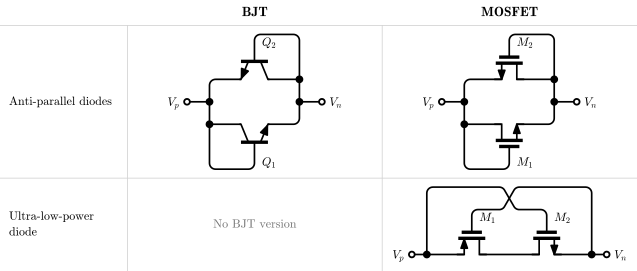

In [28]:
# HIDE/SHOW
def antiparallel_diodes(c):
    """Anti-parallel diodes"""
    t1 = c.transistor('n', (0, 0), 'cd', rot=3, name=1)
    t2 = c.transistor('n', (0, -60), 'es', rot=1, name=2)
    xl, xr = -20, 100
    c.w(t1.cd, (xl, 0), (xl, -60), t2.es); c.dot((xl, -30)); c.w((xl, -30), (xl - 30, -30)); c.port((xl - 30, -30), 'V_p', 'l')
    c.w(t1.es, (xr, 0), (xr, -60), t2.cd); c.dot((xr, -30)); c.w((xr, -30), (xr + 30, -30)); c.port((xr + 30, -30), 'V_n', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] + 20), (xl, t1.bg[1] + 20), (xl, 0)); c.dot((xl, 0))
    c.w(t2.bg, (t2.bg[0], t2.bg[1] - 20), (xr, t2.bg[1] - 20), (xr, -60)); c.dot((xr, -60))


def low_leakage_diode(c):
    """- | Ultra-low-power diode"""
    t1 = c.transistor('p', (0, 0), 'es', side='right', rot=3, name=1)
    t2 = c.transistor('n', (100, 0), 'cd', side='right', rot=3, name=2)
    c.w(t1.cd, t2.cd)
    c.w(t1.es, (-20, 0)); c.dot((-20, 0)); c.w((-20, 0), (-40, 0)); c.port((-40, 0), 'V_p', 'l')
    c.w(t2.es, (200, 0)); c.dot((200, 0)); c.w((200, 0), (220, 0)); c.port((220, 0), 'V_n', 'r')
    y1, y2 = -60, -90
    xl, xr = c.cross(90, y1, y2)                            # the two wires cross as an X
    c.w(t1.bg, (t1.bg[0], y1), (xl, y1), (xr, y2), (200, y2), (200, 0))
    c.w(t2.bg, (t2.bg[0], y1), (xr, y1), (xl, y2), (-20, y2), (-20, 0))

show(antiparallel_diodes, low_leakage_diode)

| | BJT | MOSFET |
|---|---|---|
| **29. Anti-parallel diodes** | Conducts when $\lvert V_p-V_n\rvert$ reaches $V_{BE}$ | Conducts when $\lvert V_p-V_n\rvert$ exceeds $V_{TH}$ |
| **30. Ultra-low-power diode** | *No BJT version.* Reverse bias does not turn a BJT further off | Reverse bias drives both gate-source voltages negative, so the leakage falls far below that of one device |

### Level Shift and Linear I-to-V Converter

Both circuits put two base-emitter or gate-source voltages in series.

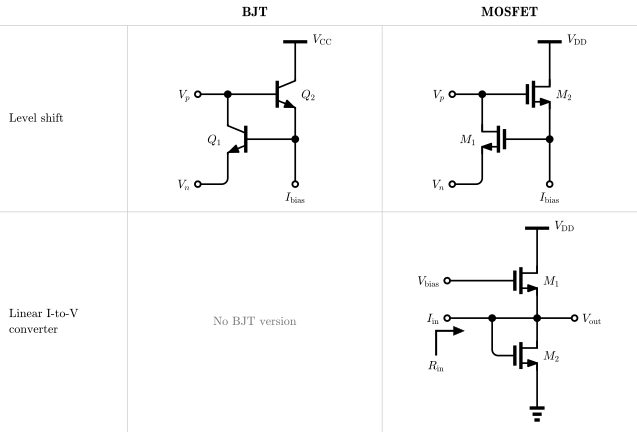

In [29]:
# HIDE/SHOW
def level_shift(c):
    """Level shift"""
    t2 = c.transistor('n', (0, 0), 'cd', name=2)
    c.supply((0, -20)); c.w((0, -20), t2.cd)
    node = (0, 100)
    c.w(t2.es, node); c.dot(node); c.w(node, (0, 160)); c.port((0, 160), 'I_bias', 'b')
    t1 = c.transistor('n', (-50, 100), 'bg', side='right', name=1)
    c.w(t1.bg, node)
    c.w(t1.cd, (t1.cd[0], 40)); c.dot((t1.cd[0], 40)); c.w((t1.cd[0], 40), (t1.cd[0] - 40, 40)); c.port((t1.cd[0] - 40, 40), 'V_p', 'l')
    c.w((t1.cd[0], 40), t2.bg)
    c.w(t1.es, (t1.es[0], 160), (t1.es[0] - 40, 160)); c.port((t1.es[0] - 40, 160), 'V_n', 'l')


def linear_i_to_v(c):
    """- | Linear I-to-V converter"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    term, tx = -120, -60
    c.w(t1.bg, (term, t1.bg[1])); c.port((term, t1.bg[1]), 'V_bias', 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')
    c.w(j, (term, j[1])); c.dot((tx, j[1])); c.port((term, j[1]), 'I_in', 'l'); c.look((term, j[1]), 'r', 'd', 'R_in')
    c.w((tx, j[1]), (tx, t2.bg[1]), t2.bg)

show(level_shift, linear_i_to_v)

| | BJT | MOSFET |
|---|---|---|
| **31. Level shift** | $V_p-V_n=V_{BE1}+V_{BE2}$ | $V_p-V_n=V_{GS1}+V_{GS2}$ |
| **32. Linear I-to-V converter** | *No BJT version.* The exponential law gives a $\sinh$ characteristic, not a straight line | $V_{GS1}+V_{GS2}=V_\mathrm{bias}$: the square-law terms cancel and $R_\mathrm{in}=\dfrac{dV_\mathrm{out}}{dI_\mathrm{in}}=\dfrac{1}{g_{m1}+g_{m2}}$ is constant |

## Switched Circuits

One device is a switch or a diode. The other is a second switch or a capacitor.

### Transmission Gate and Multiplexer

Pass devices connect or isolate two nodes. Two complementary devices in parallel make a switch for the full signal range. Two devices with a common output select one of two inputs.

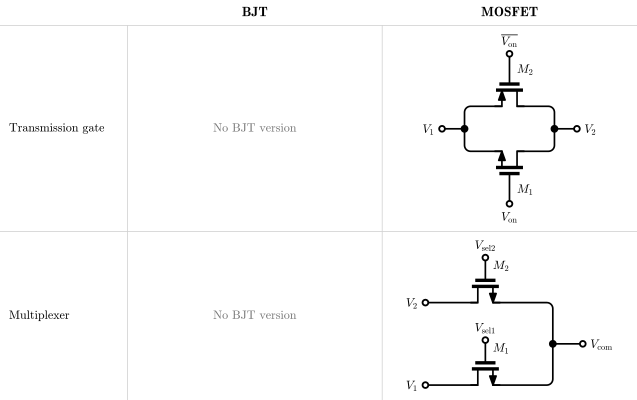

In [30]:
# HIDE/SHOW
def transmission_gate(c):
    """- | Transmission gate"""
    t1 = c.transistor('n', (0, 0), 'es', side='right', rot=1, name=1)
    t2 = c.transistor('p', (0, -60), 'es', side='right', rot=3, name=2)
    xl, xr = -20, 100
    c.w(t1.es, (xl, 0), (xl, -60), t2.es); c.dot((xl, -30)); c.w((xl, -30), (xl - 30, -30)); c.port((xl - 30, -30), 'V_1', 'l')
    c.w(t1.cd, (xr, 0), (xr, -60), t2.cd); c.dot((xr, -30)); c.w((xr, -30), (xr + 30, -30)); c.port((xr + 30, -30), 'V_2', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] + 30)); c.port((t1.bg[0], t1.bg[1] + 30), 'V_on', 'b')
    c.w(t2.bg, (t2.bg[0], t2.bg[1] - 30)); c.port((t2.bg[0], t2.bg[1] - 30), '!V_on', 't')


def multiplexer(c):
    """- | Multiplexer"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    t2 = c.transistor('n', (0, -110), 'cd', side='right', rot=3, name=2)
    for t, nm in ((t1, 'V_1'), (t2, 'V_2')):
        c.w(t.cd, (t.cd[0] - 40, t.cd[1])); c.port((t.cd[0] - 40, t.cd[1]), nm, 'l')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), 'V_sel1', 't')
    c.w(t2.bg, (t2.bg[0], t2.bg[1] - 20)); c.port((t2.bg[0], t2.bg[1] - 20), 'V_sel2', 't')
    xc, yc = 130, -55
    c.w(t1.es, (xc, 0), (xc, yc)); c.dot((xc, yc)); c.w(t2.es, (xc, -110), (xc, yc))
    c.w((xc, yc), (xc + 40, yc)); c.port((xc + 40, yc), 'V_com', 'r')

show(transmission_gate, multiplexer)

| | BJT | MOSFET |
|---|---|---|
| **33. Transmission gate** | *No BJT version.* A BJT switch injects its base current into the signal path | $M_1$ passes low levels and $M_2$ high levels, so the switch conducts from rail to rail |
| **34. Multiplexer** | *No BJT version.* A BJT switch injects its base current into the signal path | $V_\mathrm{com}=V_1$ or $V_2$, depending on which select input is high |

### Sample-and-Hold and Low-Pass Filter

A pass device feeds a node that the second device loads as a capacitor. With a clock on the gate the circuit samples. With a fixed bias it filters.

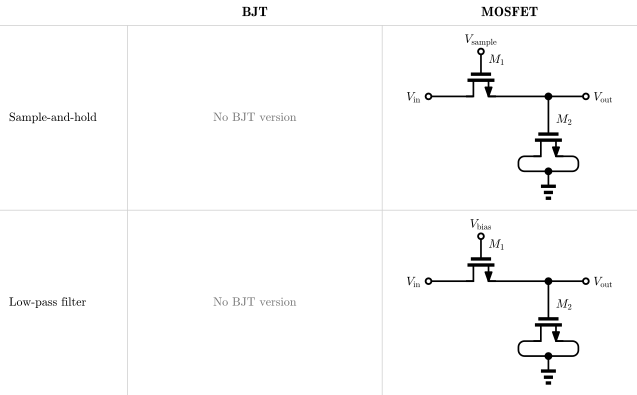

In [31]:
# HIDE/SHOW
def sample_and_hold(c):
    """- | Sample-and-hold"""
    pass_device_and_capacitor(c, 'V_sample')


def low_pass(c):
    """- | Low-pass filter"""
    pass_device_and_capacitor(c, 'V_bias')

show(sample_and_hold, low_pass)

| | BJT | MOSFET |
|---|---|---|
| **35. Sample-and-hold** | *No BJT version.* There is no gate capacitance to hold the sample, and base current would disturb it | $M_1$ on: $V_\mathrm{out}$ tracks $V_\mathrm{in}$. $M_1$ off: the gate capacitance of $M_2$ holds it |
| **36. Low-pass filter** | *No BJT version.* Neither a linear resistor nor a gate capacitance is available | $f_{-3\,\mathrm{dB}}=\dfrac{1}{2\pi R_\mathrm{on1}C_2}$ |

### Peak Detector and Voltage Doubler

A diode-connected device and a capacitor-connected device rectify. Their order decides the function.

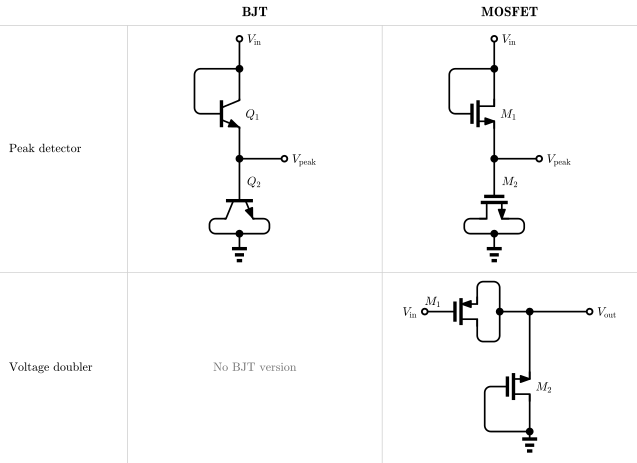

In [32]:
# HIDE/SHOW
def peak_detector(c):
    """Peak detector"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    top = (0, -20)
    c.w(t1.cd, top); c.dot(top); c.w(top, (0, -60)); c.port((0, -60), IN, 'r')
    c.w(top, (-60, -20), (-60, t1.bg[1]), t1.bg)
    pk = (0, 100)
    c.w(t1.es, pk); c.dot(pk); c.w(pk, (60, 100)); c.port((60, 100), 'V_peak', 'r')
    capacitor_to_ground(c, pk)


def voltage_doubler(c):
    """- | Voltage doubler"""
    t1 = c.transistor('p', (0, 0), 'es')
    t1.name(1, 'l', dy=-14)
    bar = 30
    c.w(t1.es, (bar, 0), (bar, 80), t1.cd)
    c.dot((bar, 40)); c.w((bar, 40), (150, 40)); c.port((150, 40), OUT, 'r')
    c.w(t1.bg, (-70, 40)); c.port((-70, 40), IN, 'l')
    t2 = c.transistor('n', (70, 100), 'es', side='right', rot=2, name=2, lbl='r')
    c.w(t2.es, (70, 40)); c.dot((70, 40))
    gy = t2.cd[1] + 20
    c.w(t2.cd, (70, gy)); c.dot((70, gy)); c.gnd((70, gy))
    c.w(t2.bg, (t2.bg[0] - 20, t2.bg[1]), (t2.bg[0] - 20, gy), (70, gy))

show(peak_detector, voltage_doubler)

| | BJT | MOSFET |
|---|---|---|
| **37. Peak detector** | *Limited.* $V_\mathrm{peak}=\hat V_\mathrm{in}-V_{BE1}$, held only on a junction capacitance | $V_\mathrm{peak}=\hat V_\mathrm{in}-V_{GS1}$, held on the gate capacitance of $M_2$ |
| **38. Voltage doubler** | *No BJT version.* The coupling element would be a junction, which conducts in one direction | $M_1$ couples the ac input and $M_2$ clamps the low side: the output peaks near $2\hat V_\mathrm{in}-V_{GS2}$ |

## Logic Gates

Each device is a switch controlled by a logic level.

### NAND and NOR

Two switches in series conduct only when both are on. Two switches in parallel conduct when either is on. The current source pulls the output high otherwise.

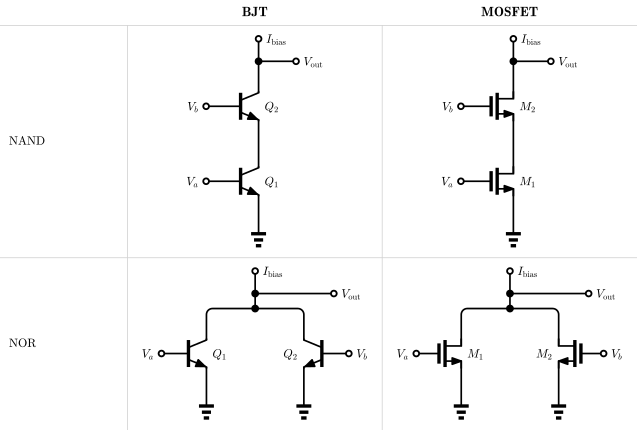

In [33]:
# HIDE/SHOW
def nand(c):
    """NAND"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    for t, nm in ((t1, 'V_a'), (t2, 'V_b')):
        c.w(t.bg, (t.bg[0] - 30, t.bg[1])); c.port((t.bg[0] - 30, t.bg[1]), nm, 'l')
    top = (0, -20); c.w(t2.cd, top); c.dot(top); c.w(top, (50, top[1])); c.port((50, top[1]), OUT, 'r')
    c.w(top, (0, -50)); c.port((0, -50), 'I_bias', 'r')


def nor(c):
    """NOR"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (130, 0), 'cd', side='right', name=2)
    for t in (t1, t2):
        g = (t.es[0], t.es[1] + 20); c.gnd(g); c.w(t.es, g)
    mx = 65
    c.w(t1.bg, (t1.bg[0] - 20, t1.bg[1])); c.port((t1.bg[0] - 20, t1.bg[1]), 'V_a', 'l')
    c.w(t2.bg, (t2.bg[0] + 20, t2.bg[1])); c.port((t2.bg[0] + 20, t2.bg[1]), 'V_b', 'r')
    yt = -20
    c.w(t1.cd, (0, yt), (130, yt)); c.w(t2.cd, (130, yt)); c.dot((mx, yt))
    top = (mx, -40); c.w((mx, yt), top); c.dot(top); c.w(top, (170, top[1])); c.port((170, top[1]), OUT, 'r')
    c.w(top, (mx, -70)); c.port((mx, -70), 'I_bias', 'r')

show(nand, nor)

| | BJT | MOSFET |
|---|---|---|
| **39. NAND** | $V_\mathrm{out}=\overline{V_a\wedge V_b}$. The inputs must supply base current | $V_\mathrm{out}=\overline{V_a\wedge V_b}$ |
| **40. NOR** | $V_\mathrm{out}=\overline{V_a\vee V_b}$. The inputs must supply base current | $V_\mathrm{out}=\overline{V_a\vee V_b}$ |

### XNOR and Mixer

Both circuits multiply. The XNOR gate multiplies two logic signs. The mixer multiplies two analog signals.

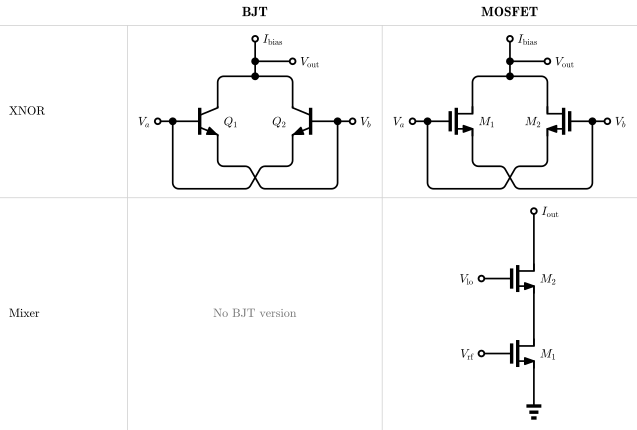

In [34]:
# HIDE/SHOW
def xnor(c):
    """XNOR"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (100, 0), 'cd', side='right', name=2)
    mx = 50
    ga = (t1.bg[0] - 20, t1.bg[1]); gb = (t2.bg[0] + 20, t2.bg[1])
    c.w(t1.bg, ga); c.dot(ga); c.w(ga, (ga[0] - 20, ga[1])); c.port((ga[0] - 20, ga[1]), 'V_a', 'l')
    c.w(t2.bg, gb); c.dot(gb); c.w(gb, (gb[0] + 20, gb[1])); c.port((gb[0] + 20, gb[1]), 'V_b', 'r')
    yt = -20
    c.w(t1.cd, (0, yt), (mx, yt)); c.w(t2.cd, (100, yt), (mx, yt)); c.dot((mx, yt))
    c.w((mx, yt), (mx, -40)); c.dot((mx, -40)); c.w((mx, -40), (100, -40)); c.port((100, -40), OUT, 'r')
    c.w((mx, -40), (mx, -70)); c.port((mx, -70), 'I_bias', 'r')
    y1, y2 = t1.es[1] + 20, t1.es[1] + 50
    xl, xr = c.cross(mx, y1, y2)                            # the two wires cross as an X
    c.w(t1.es, (0, y1), (xl, y1), (xr, y2), (gb[0], y2), gb)
    c.w(t2.es, (100, y1), (xr, y1), (xl, y2), (ga[0], y2), ga)


def mixer(c):
    """- | Mixer"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t2.cd, (0, -50)); c.port((0, -50), 'I_out', 'r')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_lo', 'l')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_rf', 'l')

show(xnor, mixer)

| | BJT | MOSFET |
|---|---|---|
| **41. XNOR** | *Limited.* The conducting device draws its base current from one input and returns it to the other | Each input drives the gate of one device and the source of the other: $V_\mathrm{out}=\overline{V_a\oplus V_b}$ |
| **42. Mixer** | *No BJT version.* In the active region the collector current does not depend on $V_{CE}$, so an upper base would have no control | $M_1$ works in triode, where $I_\mathrm{out}\approx\mu_nC_{ox}\tfrac{W}{L}(V_\mathrm{rf}-V_{TH})\,V_{DS1}$ and $V_\mathrm{lo}$ sets $V_{DS1}$: the output contains the product |

## Symbols

The symbols used on this page, at one scale. Their proportions were measured from the figures of [2]. The BJT and the MOSFET share one footprint, so the two versions of every circuit line up.

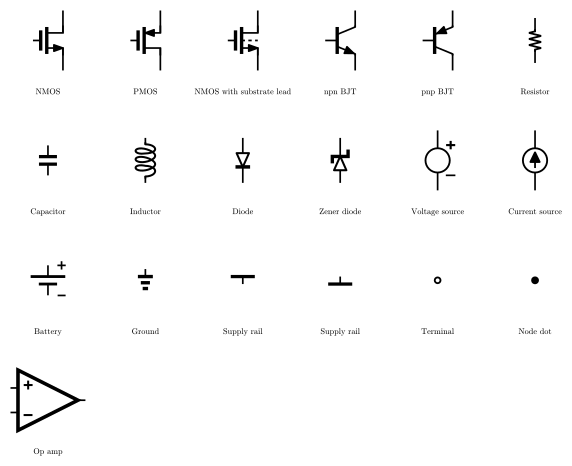

In [35]:
# HIDE/SHOW
symbol_sheet()

## References

1. H. Pretl and M. Eberlein, "Fifty Nifty Variations of Two-Transistor Circuits: A tribute to the versatility of MOSFETs," *IEEE Solid-State Circuits Magazine*, vol. 13, no. 3, pp. 38-46, 2021. [doi:10.1109/MSSC.2021.3088968](https://doi.org/10.1109/MSSC.2021.3088968). Web edition with the drawing code: [iic-jku.github.io/fifty-nifty-circuits](https://iic-jku.github.io/fifty-nifty-circuits/).
2. B. Razavi, *Fundamentals of Microelectronics*, 2nd ed., Wiley, 2013.